In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import halfnorm, beta, lognorm

Let's say we want to estimate the TV adstock parameter, alpha. We know from our synthetic data that the true value is 0.65, but imagine we didn't know that.

We could set the prior as a $\alpha \sim Beta(2,2)$ distribution.

Then update the prior using the observed data (likelihood) to obtain the posterior and credible interval for alpha.

**Question 1:**
Suppose our Bayesian model estimates TV's incremental revenue contribution at $40,000, with a 95% credible interval of $30,000–$50,000.

How would you explain that result to FreshBite's marketing director?

Answer 1: Based on our prior and the observed data - we believe there is a 95% chance that the incremental revenue contribution of TV is in the range of $30,000-$50,000, with our best estimate being $40,000.

**Question 2:**
Why might we want to incorporate prior knowledge about advertising effectiveness rather than allowing the observed data to determine everything?

Answer 2: If we only allow the observed data to determine anything, it could result in unnecessarily high uncertainty when we have a low quantity of data - the benefit of using a prior is to "seed" our model with reasonable assumptions (our prior) based on existing understanding. Especially in a situation such as marketing, this is more reasonable than assuming that we should rely only on observed data, which may produce unnecessarily wide credible intervals when the number of observations is lower.

**Question 3:**
Suppose our prior belief about TV alpha is centered at 0.5, but after observing the data, our posterior is centered at 0.65.

What does this tell us about the relationship between prior beliefs and observed data?

Answer 3: It tells us that our prior belief about alpha was lower than the current estimate of alpha based on the latest data collected. It doesn't necessarily mean our prior was inaccurate (it could have been accurate at some point in time), but it does mean that the current alpha appears to be meaningfully higher than our prior - note, it also depends on how much weight we place on our prior. The heavier weight we placed on the prior, the more meaningful a significant change in the posterior is.

### Defining the parameters for our Freshbite Model

* $\alpha_j$ - Advertising carryover
* $EC50_j$ - Saturation point
* $\beta_j$ - Maximum channel contribution scale
* $\sigma$ - Residual noise

### Defining the priors for each parameter

$\alpha_j \sim Beta(2,2)$

This is a reasonable starting point when we don't have strong channel-specific prior information.

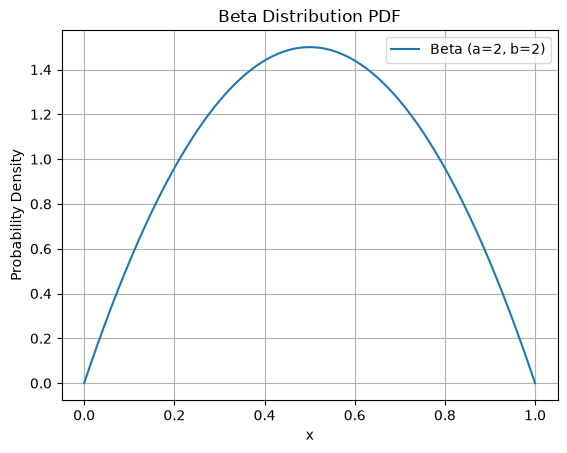

In [9]:
a, b = 2, 2
x = np.linspace(0, 1, 200)
pdf = beta.pdf(x, a, b)

plt.plot(x, pdf, label=f"Beta (a={a}, b={b})")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.title("Beta Distribution PDF")
plt.legend()
plt.grid(True)
plt.show()

$\beta_j \sim HalfNormal(1)$

Assuming marketing has a non-negative incremental effect, we can use this as a prior.

Note: this scale assumes the outcome and predictors have been appropriately standardized. We shouldn't blindly use this prior with raw revenue measured in dollars.

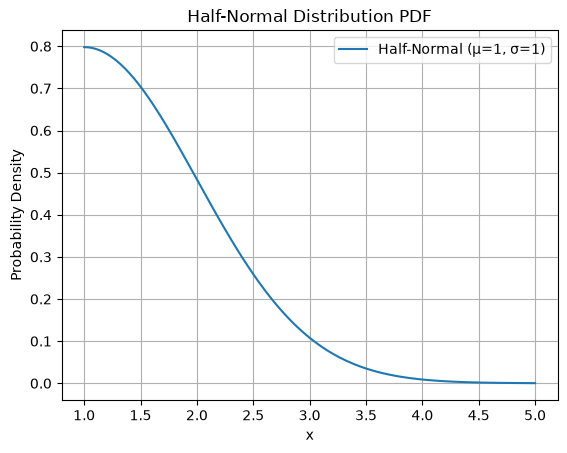

In [6]:
mu, sigma = 1, 1
x = np.linspace(mu, mu + 4 * sigma, 200)
pdf = halfnorm.pdf(x, loc=mu, scale=sigma)

plt.plot(x, pdf, label=f"Half-Normal (μ={mu}, σ={sigma})")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.title("Half-Normal Distribution PDF")
plt.legend()
plt.grid(True)
plt.show()

$EC50j \sim LogNormal(\mu, \sigma)$

We can use a lognormal prior for EC50, to ensure that EC 50 is positive.

The parameters need to be chosen based on the spend units and plausible saturation ranges.

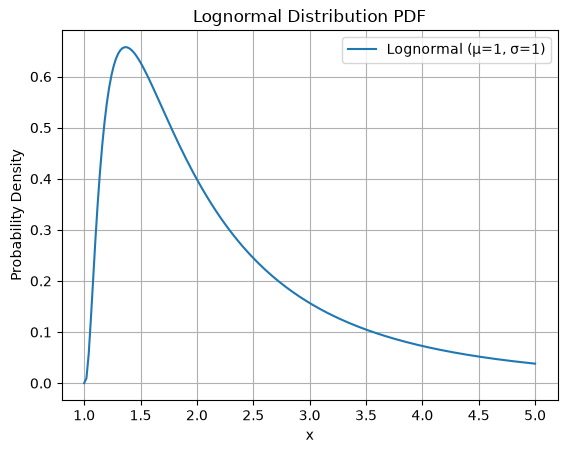

In [15]:
mu, sigma = 1, 1
x = np.linspace(mu, mu + 4 * sigma, 200)

pdf = lognorm.pdf(x, s=sigma, loc=mu)

plt.plot(x, pdf, label=f"Lognormal (μ={mu}, σ={sigma})")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.title("Lognormal Distribution PDF")
plt.legend()
plt.grid(True)
plt.show()

### Test your understanding:

**Question 1: Why might a Beta distribution be more appropriate than a Normal distribution for alpha?**

Answer 1: It's more appropriate because the Beta distribution takes values between 0 and 1, which is appropriate for the $\alpha$ parameter. A normal distribution would produce invalid parameter values.

**Question 2: Why might a LogNormal distribution be appropriate for EC50?**

Answer 2: Because it's a strictly positive distribution covering a wide range of values.

Bonus: We use a halfnormal distribution also when we need a positive distribution, but when the expected value is near zero.

**Question 3: Suppose we choose a very narrow prior centered at alpha = 0.5, but the true value is 0.9. What potential problem could this create in our model?**

Answer 3: It could cause the model to be inappropriately biased towards 0.5 - and take a long time (a lot of observations) to converge towards the true value. This will result in inaccurate estimates of alpha until a significant number of observations are collected.

### Likelihood - test your understanding

Suppose our likelihood model is specified as follows:
$$
\hat y_t = \text{baseline}_t + \text{marketing contribution}_t
$$

We might assume actual revenue follows a Normal distribution around the prediction:

$$
y_t \sim \mathcal{N}(\hat y_t,\sigma)
$$

Here, $\sigma$ represents unexplained variation: factors the model doesn't capture, plus random noise.


Three questions to check your understanding:

**1. If our model predicts revenue of \\$200,000 for a week, what does the likelihood tell us about the probability of observing actual revenue of \\$198,000?**

Answer 1: We can compute the probability of observing revenue of at least \\$198,000 by using the Normal distribution centered at \\$200,000 along with the current value of $\sigma$.

Specifically, if $\sigma = 5000$ (example) - the standardized residual (error / sigma) is -0.4, meaning the true value is only 0.4 standard deviations below the prediction, so it is quite compatible with our model.
 
**2. What would a very large value of \(\sigma\) mean about our model's ability to predict revenue?**

Answer 2: It means that our model is unable to predict revenue with high precision - all of our predictions will have a wide range of possible values included in the credible interval.

**3. Why might assuming normally distributed errors be a reasonable starting point for FreshBite, but not necessarily the best final choice?**

Answer 3: If we eventually understand errors to follow a non-normal distribution (for example, our model more often overestimates vs. underestimates), then we should adjust the errors to take a non-normal distribution. This will allow our predictions to reflect our belief / understanding of the world based on what we've observed (under the fixed model specification).

Refinement:
Systematic overprediction or underprediction isn't necessarily evidence that the errors are non-normal. It could indicate a misspecified model, such as a missing trend, seasonal effect, or control variable. We should also distinguish:
* Skewed errors - the residual distribution is truly asymmetric
* Biased predictions - residuals systematically tend to be positive or negative
* Heavy-tailed errors - Extreme deviations occur more often than a normal distribution predicts (in this case, a t-distribution may be more appropriate)